#Student Name:Dilire Hezierhan

#Read a tabular dataset(xlsx or CSV) from the https://data.mendeley.com/ and then solve the following steps

In [48]:
#Read dataset
import pandas as pd
data=pd.read_excel('iris.xlsx')

In [49]:
#check the number of sheet and then print your dataset
data1=pd.ExcelFile('iris.xlsx')
data1.sheet_names

['iris-write-from-docker']

In [50]:
data

,sepal_length,sepal_width,petal_length,petal_width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


In [51]:
#check data type and dataset should have object type of data; Apply label encoder on your row dataset to change the datatype to int or float
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   class         150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [52]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
import warnings as wr # for Handle Error
import numpy as np
le=LabelEncoder()
wr.filterwarnings('ignore')
for col in data.columns:
    if data[col].dtype==np.number:
        continue
    data[col]=le.fit_transform(data[col])
data

,sepal_length,sepal_width,petal_length,petal_width,class
0,8,14,4,1,0
1,6,9,4,1,0
2,4,11,3,1,0
3,3,10,5,1,0
4,7,15,4,1,0
...,...,...,...,...,...
145,24,9,28,19,2
146,20,4,26,15,2
147,22,9,28,16,2
148,19,13,30,19,2


In [53]:
#check NAN in your dataset; if there is any NAN, clean it; Hints: dropna/fillna()
data.isnull().sum()

,0
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
class,0


DataFrame Head:


,sepal_length,sepal_width,petal_length,petal_width,class
0,8,14,4,1,0
1,6,9,4,1,0
2,4,11,3,1,0


DataFrame Tail:


,sepal_length,sepal_width,petal_length,petal_width,class
147,22,9,28,16,2
148,19,13,30,19,2
149,16,9,27,14,2


----------------------------------------------------------------------------------------------------
Missing values:


,0


----------------------------------------------------------------------------------------------------
Shape of DataFrame:

(150, 5)

----------------------------------------------------------------------------------------------------
DataFrame Info:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   sepal_length  150 non-null    int64
 1   sepal_width   150 non-null    int64
 2   petal_length  150 non-null    int64
 3   petal_width   150 non-null    int64
 4   class         150 non-null    int64
dtypes: int64(5)
memory usage: 6.0 KB
----------------------------------------------------------------------------------------------------
Describe DataFrame:



,count,mean,median,std,min,25%,50%,75%,max,skewness,kurtosis
sepal_length,150,15.387,15,8.176,0,8,15,21,34,0.253715,-0.704728
sepal_width,150,9.54,9,4.3,0,7,9,12,22,0.321957,0.098093
petal_length,150,18.2,19.5,11.649,0,6,19.5,27,42,0.138365,-1.222474
petal_width,150,8.987,9,6.406,0,2,9,14,21,0.118579,-1.228417
class,150,1,1,0.819,0,0,1,2,2,0.000000,-1.500000


----------------------------------------------------------------------------------------------------
DataFrame Correlation:



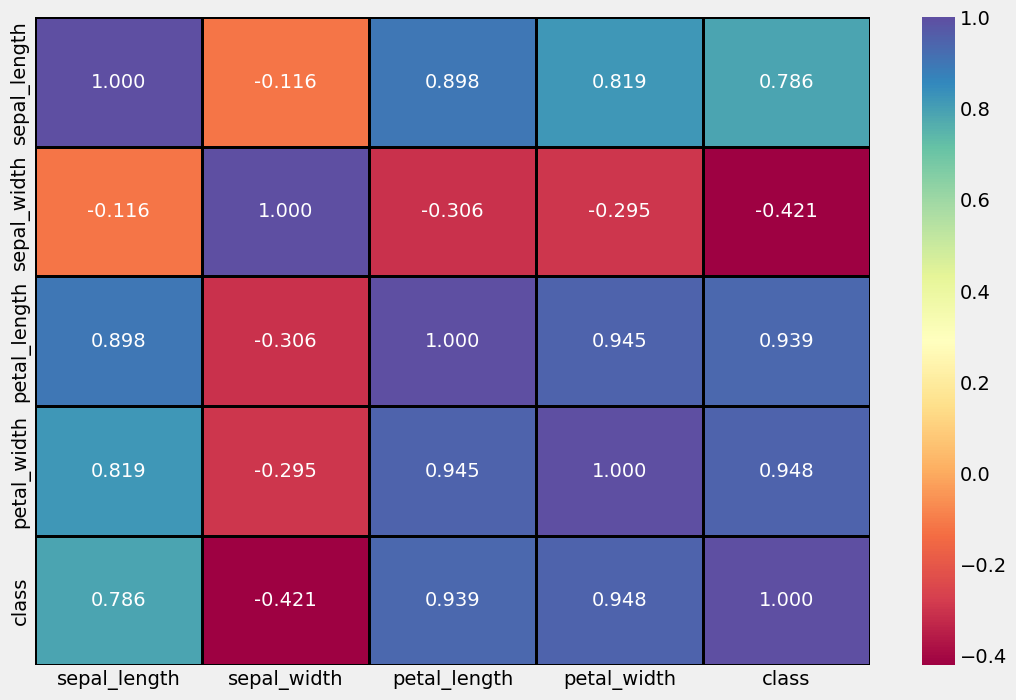

----------------------------------------------------------------------------------------------------
DataFrame Pairplot:



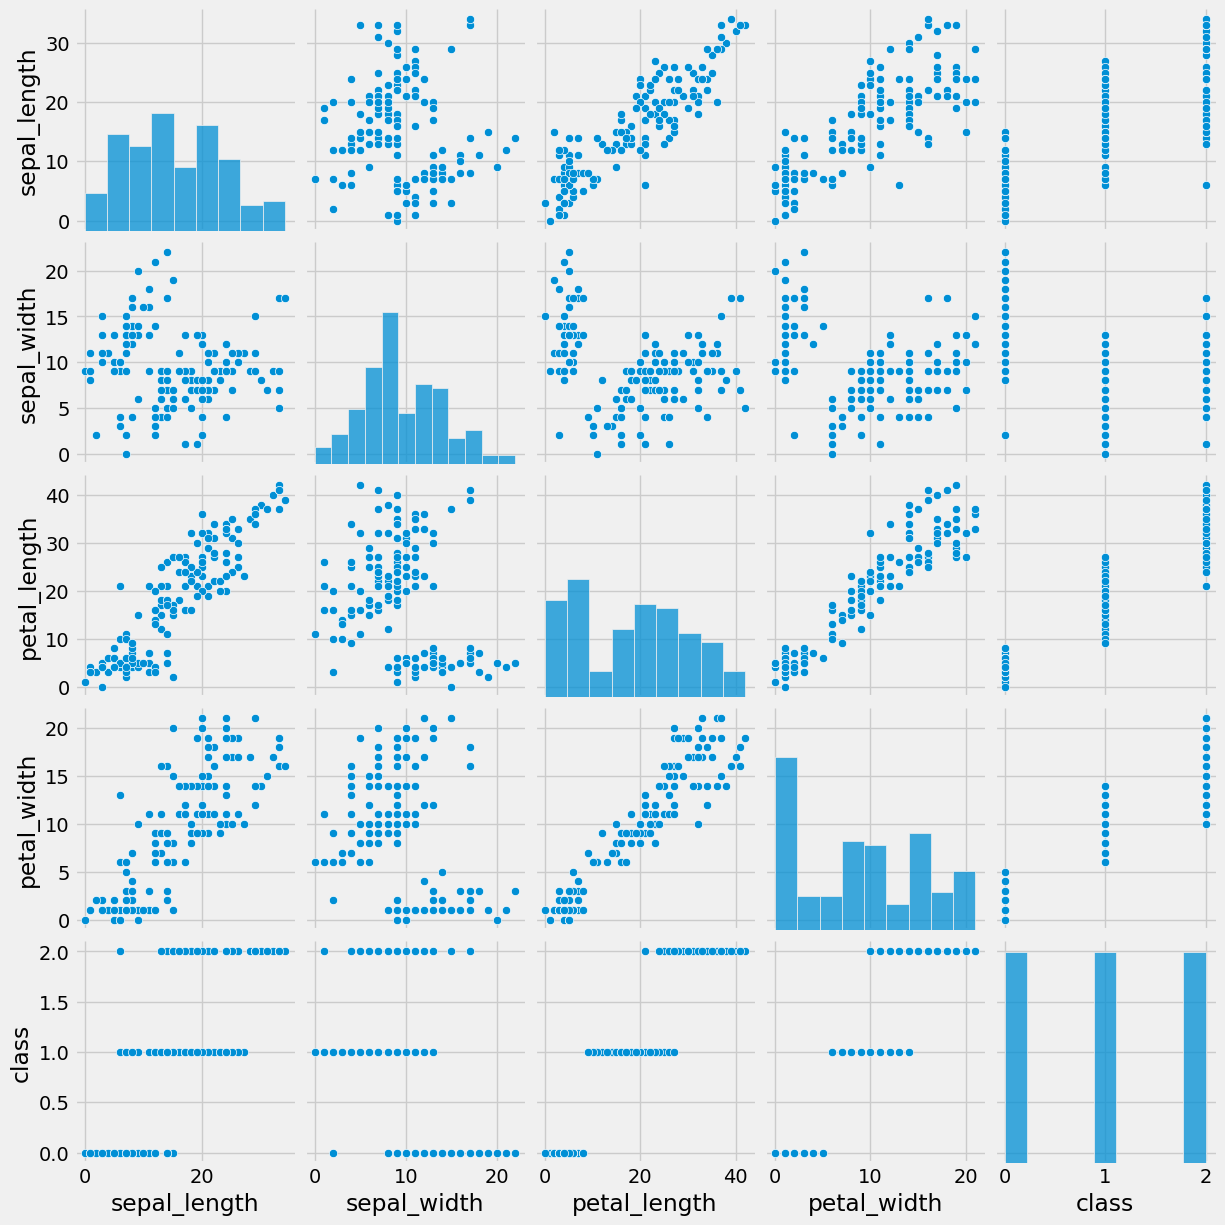

----------------------------------------------------------------------------------------------------
Histogram(s) & Boxplot(s):



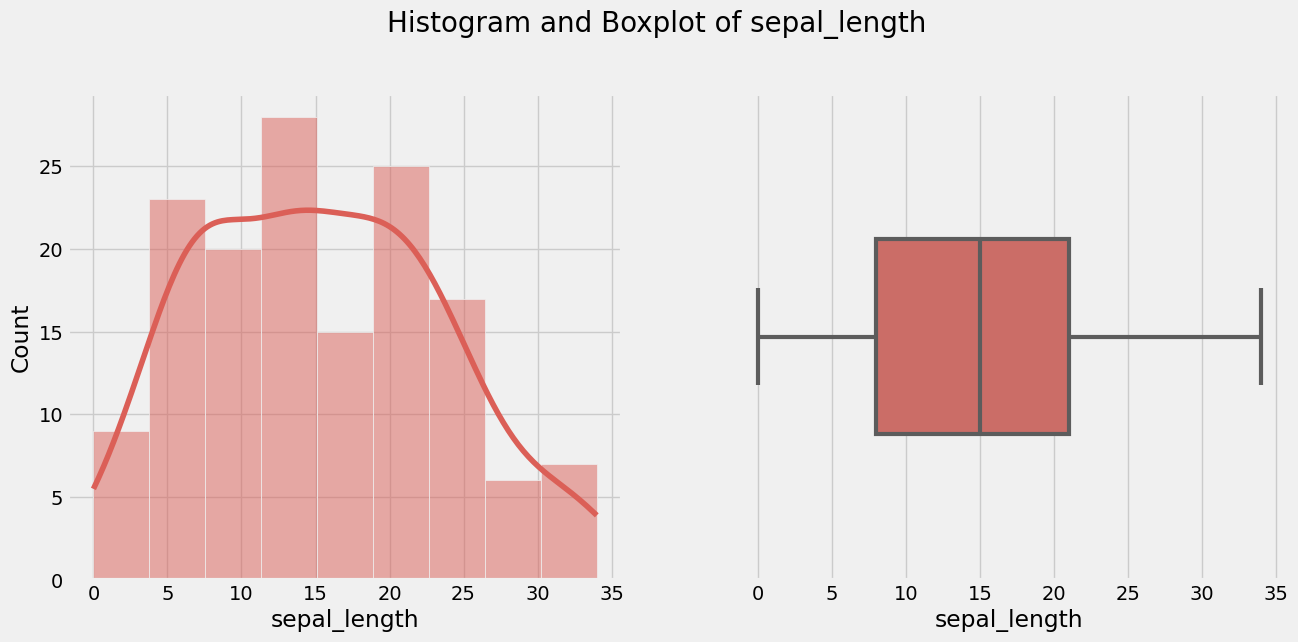

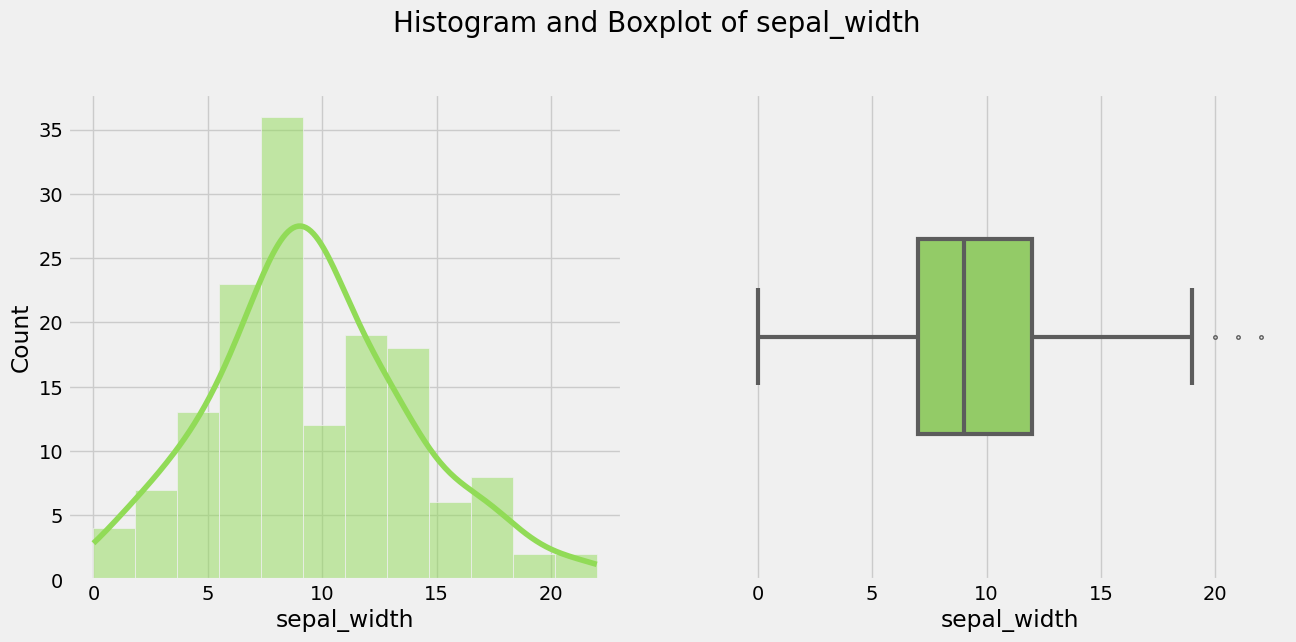

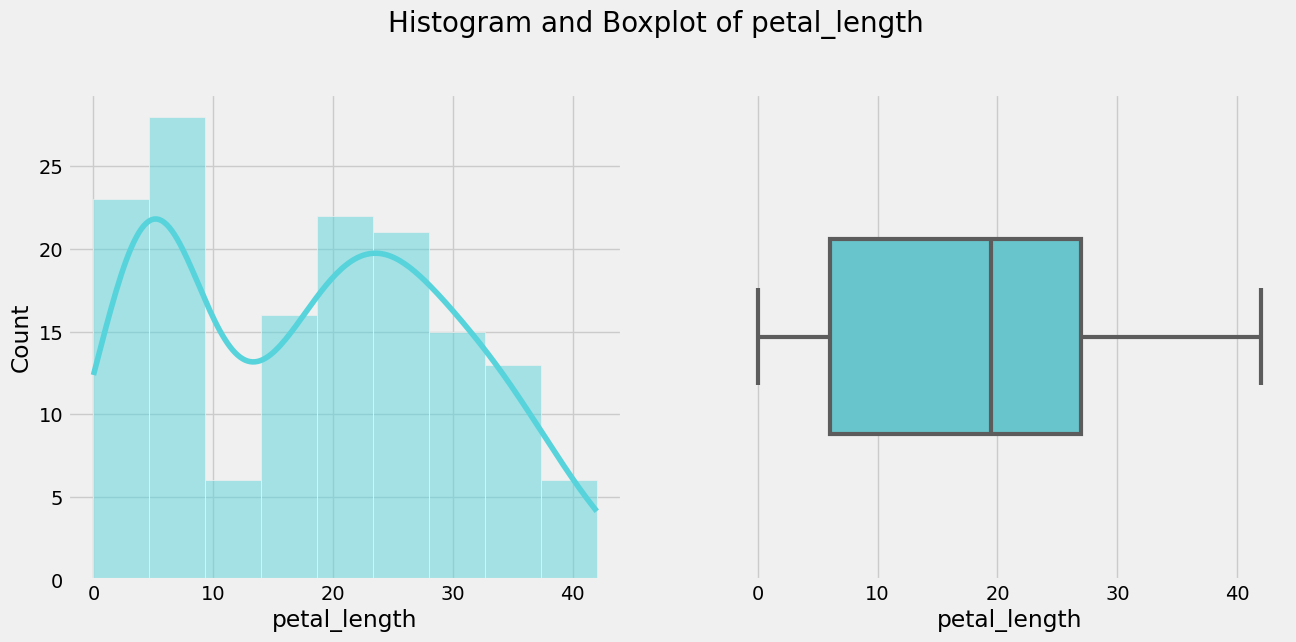

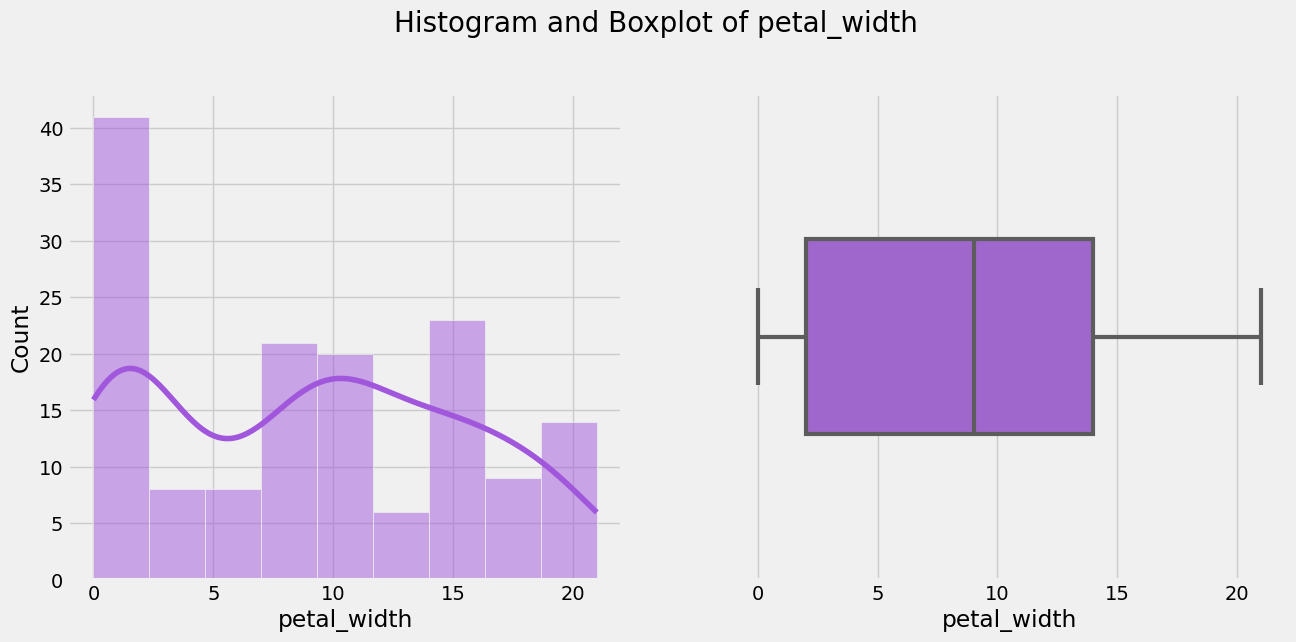

----------------------------------------------------------------------------------------------------
Countplot(s):



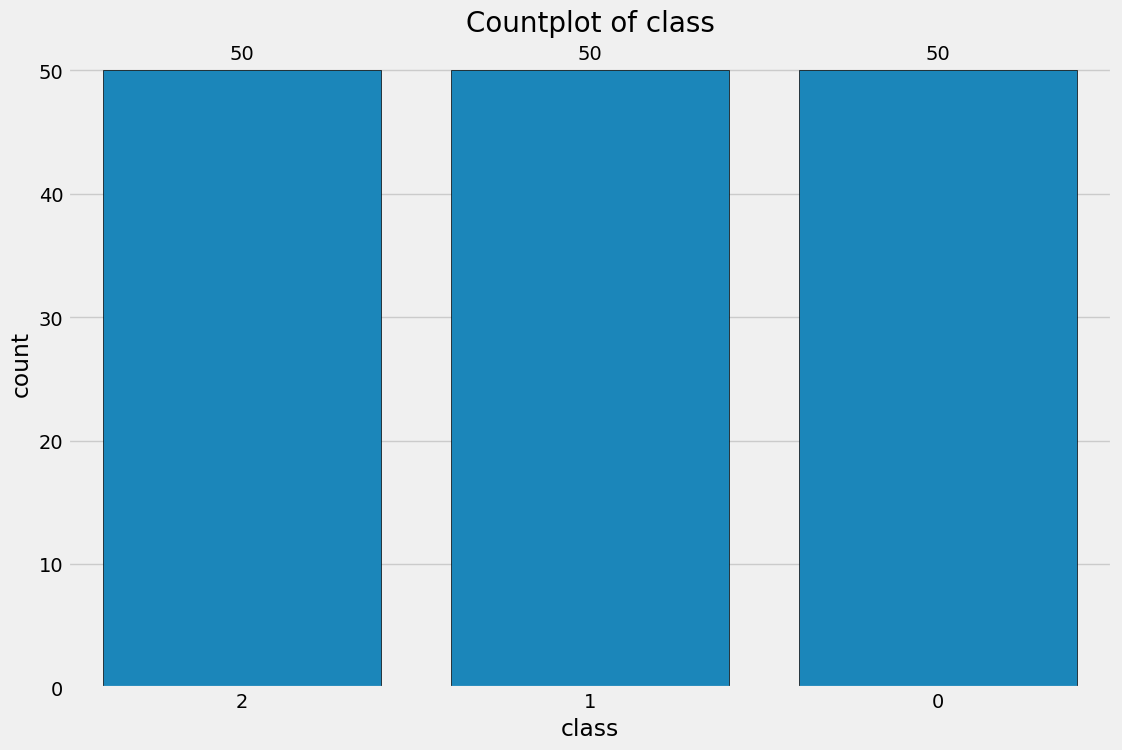

In [54]:
#Visualize dataset using fast_eda
!pip install fasteda
from fasteda import fast_eda
fast_eda(data)

#The following codes are for regression

In [55]:
# prepare X(input variable) and y(target variable)
y=data.iloc[:,-1]
y

,class
0,0
1,0
2,0
3,0
4,0
...,...
145,2
146,2
147,2
148,2


In [56]:
x=data.iloc[:,:-1]
x

,sepal_length,sepal_width,petal_length,petal_width
0,8,14,4,1
1,6,9,4,1
2,4,11,3,1
3,3,10,5,1
4,7,15,4,1
...,...,...,...,...
145,24,9,28,19
146,20,4,26,15
147,22,9,28,16
148,19,13,30,19


In [57]:
#split dataset to prepare train and test dataset; print a sample data(train/test)
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.20, random_state=0)
x_train

,sepal_length,sepal_width,petal_length,petal_width
137,21,10,31,14
84,11,9,21,11
27,9,14,5,1
127,18,9,25,14
132,21,7,32,18
...,...,...,...,...
9,6,10,5,0
103,20,8,32,14
67,15,6,17,6
117,33,17,41,18


In [58]:
# apply feature scaling and print any sample data after feature scaling
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)
x_train

array([[ 0.62920142,  0.10964301,  1.04272016,  0.72418792],
       [-0.56927748, -0.1253063 ,  0.19784224,  0.26357369],
       [-0.80897326,  1.04944025, -1.15396242, -1.27180705],
       [ 0.26965775, -0.1253063 ,  0.53579341,  0.72418792],
       [ 0.62920142, -0.59520492,  1.12720795,  1.33834022],
       [-0.80897326, -0.83015422, -0.3090845 ,  0.11003562],
       [-0.20973381,  1.75428817, -0.98498683, -1.11826898],
       [ 0.14980986, -0.83015422,  0.70476899,  0.41711177],
       [ 0.02996197, -0.1253063 , -0.05562113,  0.26357369],
       [-0.08988592, -1.06510353, -0.22459671, -0.19704053],
       [ 1.10859298, -0.1253063 ,  1.04272016,  1.18480214],
       [-1.4082127 ,  0.34459232, -1.322938  , -1.27180705],
       [ 1.22844087,  0.10964301,  0.70476899,  1.49187829],
       [-1.04866903,  1.04944025, -1.06947462, -0.65765475],
       [-0.56927748,  1.51933886, -1.15396242, -1.27180705],
       [-1.04866903, -2.23985008, -0.64703567, -0.50411668],
       [ 0.74904931, -0.

In [59]:
#apply any regressor on your dataset
from sklearn.ensemble import RandomForestRegressor
model = RandomForestRegressor(n_estimators = 500, criterion = 'squared_error', random_state = 0)
model.fit(x_train, y_train)

RandomForestRegressor(n_estimators=500, random_state=0)

In [60]:
y_pred = model.predict(x_test)

In [61]:
# measure the following performance metrics
#1. MAE, 2. MSE, 3. RMSE, 4. Prediction Score
from sklearn import metrics
print("MAE", metrics.mean_absolute_error(y_test, y_pred))
print("MSE", metrics.mean_squared_error(y_test, y_pred))
print("RMSE", np.sqrt(metrics.mean_squared_error(y_test, y_pred)))
print("Score:", model.score(x_test, y_test))

MAE 0.02533333333333334
MSE 0.005886133333333336
RMSE 0.0767211400679978
Score: 0.9890772783505155


In [62]:
#Apply the following three XAI techniques to visualize the important features based on their contribution to the results
# 1. feature_importance, 2. LIME, and 3. SHAP

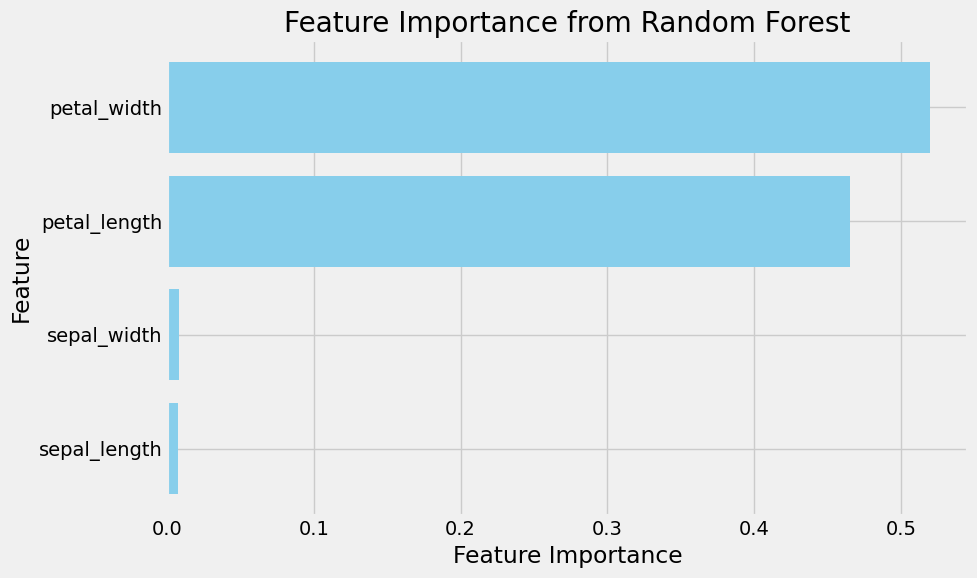

In [63]:
# 1. feature_importance
import matplotlib.pyplot as plt

importances = model.feature_importances_
feature_names = x.columns
feature_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False)

# Plot feature importances
plt.figure(figsize=(10, 6))
plt.barh(feature_imp_df['Feature'], feature_imp_df['Importance'], color='skyblue')
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Feature Importance from Random Forest")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [64]:
#2. LIME
!pip install lime

In [65]:
feature_names=x.columns

In [66]:
import lime
import lime.lime_tabular
# LIME has one explainer for all the models
# explainer = lime.lime_tabular.LimeTabularExplainer(X_train, feature_names= feature_names,
# class_names=['MEDV'], verbose=True, mode='regression')
explainer = lime.lime_tabular.LimeTabularExplainer(x_train, feature_names= feature_names,
                                                   class_names=['MEDV'], verbose=True, mode='regression')

In [67]:
explainer

In [68]:
j = 20
# exp = explainer.explain_instance(X_test, rf_regressor.predict, num_features=6)
exp = explainer.explain_instance(x_test[j], model.predict, num_features=9)

# Show the predictions
exp.show_in_notebook(show_table=True)

Intercept 0.8142440034389111
Prediction_local [1.66748307]
Right: 1.94


In [69]:
#3. SHAP
import shap

# explain the model's predictions using SHAP
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(x_train)

# visualize the first prediction's explanation
# shap.initjs()
# shap.force_plot(explainer.expected_value, shap_values[0,:], X_train[0])
# visualize the first prediction's explanation
shap.initjs()
shap.force_plot(explainer.expected_value, shap_values[0,:], x_train[0,:])

# Following codes are for classification

In [70]:
# prepare X(input variable) and y(target variable)

In [71]:
y1=data.iloc[:,-1]
y1

,class
0,0
1,0
2,0
3,0
4,0
...,...
145,2
146,2
147,2
148,2


In [72]:
x1=data.iloc[:,:-1]
x1

,sepal_length,sepal_width,petal_length,petal_width
0,8,14,4,1
1,6,9,4,1
2,4,11,3,1
3,3,10,5,1
4,7,15,4,1
...,...,...,...,...
145,24,9,28,19
146,20,4,26,15
147,22,9,28,16
148,19,13,30,19


In [73]:
# split dataset to prepare train and test dataset; print a sample data(train/test)
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x1, y1, test_size = 0.2, random_state = 0)
x_train

,sepal_length,sepal_width,petal_length,petal_width
137,21,10,31,14
84,11,9,21,11
27,9,14,5,1
127,18,9,25,14
132,21,7,32,18
...,...,...,...,...
9,6,10,5,0
103,20,8,32,14
67,15,6,17,6
117,33,17,41,18


In [74]:
# apply any dimension reduction techniques( such as PCA/LDA/Kernel PCA/ etc); print a sample data (train/test) after applying a feature reduction technique
# Applying Kernel PCA
from sklearn.decomposition import KernelPCA
kpca = KernelPCA(n_components = 2, kernel = 'rbf')
X_train = kpca.fit_transform(x_train)
X_test = kpca.transform(x_test)
X_train

array([[-0.04188216, -0.07437992],
       [-0.0288384 , -0.04799514],
       [ 0.70360762,  0.14454695],
       [-0.042407  , -0.07542023],
       [-0.04310342, -0.07708961],
       [-0.02894211, -0.04817246],
       [-0.02759394, -0.04907626],
       [-0.03165231, -0.05363854],
       [-0.0350536 , -0.06330568],
       [-0.05731024, -0.11268082],
       [-0.03768181, -0.0654463 ],
       [-0.12676305,  0.21248779],
       [-0.03184605, -0.05374749],
       [-0.00706359, -0.04669465],
       [ 0.10671767, -0.05039611],
       [-0.02920822, -0.04856041],
       [-0.04256843, -0.07571172],
       [-0.03450114, -0.05910621],
       [-0.02853453, -0.0472614 ],
       [-0.02842463, -0.04705182],
       [-0.05289505, -0.10009778],
       [-0.02880134, -0.04777505],
       [-0.02906893, -0.04830346],
       [-0.05189507, -0.09711023],
       [-0.03297993, -0.05594356],
       [-0.03018463, -0.05047174],
       [-0.02841225, -0.04702658],
       [-0.03178171, -0.05358441],
       [-0.03062039,

In [75]:
#apply any classifier on your dataset both on with and without a dimension reduction technique

In [76]:
#1.Without a dimension reduction technique
from sklearn.ensemble import RandomForestClassifier
model1 = RandomForestClassifier(n_estimators=100, criterion='entropy', random_state = 0)
model1.fit(x_train, y_train)

RandomForestClassifier(criterion='entropy', random_state=0)

In [77]:
y_pred1 = model1.predict(x_test)

In [78]:
#2.With a dimension reduction technique
from sklearn.ensemble import RandomForestClassifier
model2 = RandomForestClassifier(n_estimators=100, criterion='entropy', random_state = 0)
model2.fit(X_train, y_train)

RandomForestClassifier(criterion='entropy', random_state=0)

In [79]:
y_pred2 = model2.predict(X_test)

In [80]:
# Measure and compare the performance metrics of your classifier with and without applying a dimensionality reduction technique.
# Report the results using standard evaluation metrics (e.g., accuracy, accuracy with cross validation, confusion metrics and briefly discuss how dimensionality reduction affects the model’s performance.

In [81]:
#1. Without a dimension reduction technique(result)
model1.score(x_test, y_test)

0.9666666666666667

In [82]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred1)
cm

array([[11,  0,  0],
       [ 0, 13,  0],
       [ 0,  1,  5]])

In [83]:
#run 10 times to get result score( k-fold Cross Validation)
from sklearn.model_selection import cross_val_score
accuracies = cross_val_score(estimator = model1, X = x_train, y = y_train, cv = 10)
accuracies

array([0.91666667, 0.91666667, 0.83333333, 1.        , 1.        ,
       1.        , 0.91666667, 0.91666667, 0.91666667, 0.91666667])

In [84]:
accuracies.mean()

np.float64(0.9333333333333332)

In [85]:
#2.With a dimension reduction technique(result)
model2.score(X_test, y_test)

0.36666666666666664

In [86]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred2)
cm

array([[11,  0,  0],
       [12,  0,  1],
       [ 5,  1,  0]])

In [87]:
#run 10 times to get result score( k-fold Cross Validation)
from sklearn.model_selection import cross_val_score
accuracies = cross_val_score(estimator = model2, X = X_train, y = y_train, cv = 10)
accuracies

array([0.58333333, 0.83333333, 0.58333333, 0.91666667, 0.83333333,
       0.83333333, 0.58333333, 0.91666667, 0.58333333, 0.83333333])

In [88]:
accuracies.mean()

np.float64(0.75)

Overall,I discovered that, when I used dimension reduction technique, the accuracy score is reduced. And I think the main reason of this phenomenon is that accuracy decreased after applying Kernel PCA because dimensionality reduction can remove discriminative information, especially when the reduced feature space does not preserve class-relevant structures needed by the classifier.


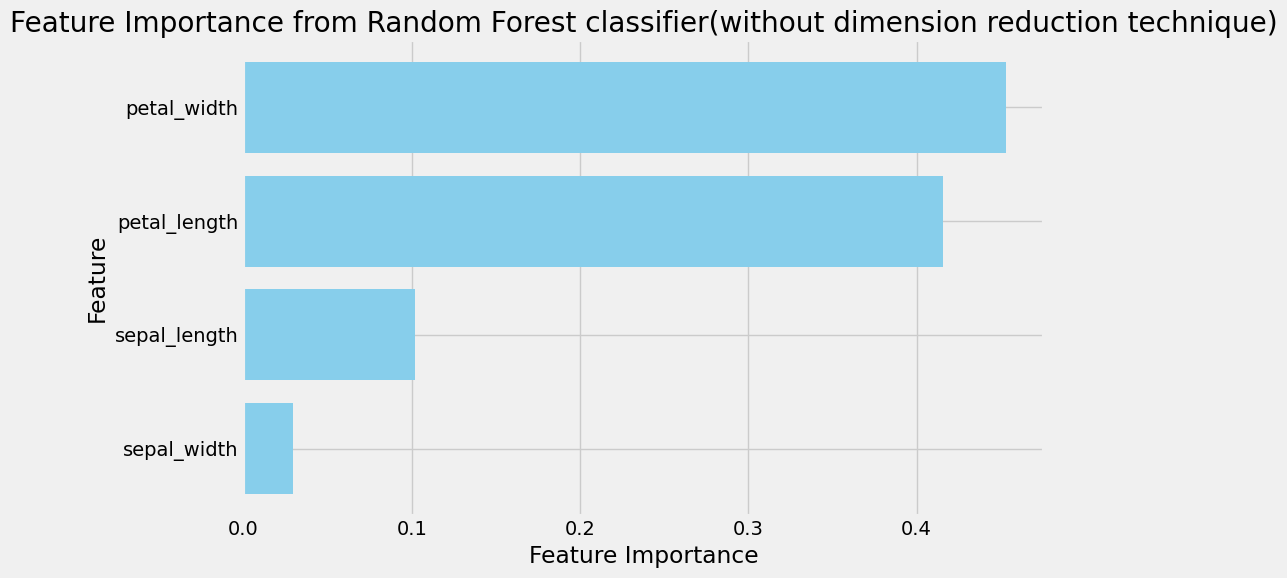

In [89]:
#Apply the following three XAI techniques to the classifier model(without dimension reduction technique) to visualize the important features based on their contribution to the results
# 1. feature_importance, 2. LIME, and 3. SHAP
#1. feature_importance
import matplotlib.pyplot as plt

importances = model1.feature_importances_
feature_names = x.columns
feature_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False)

# Plot feature importances
plt.figure(figsize=(10, 6))
plt.barh(feature_imp_df['Feature'], feature_imp_df['Importance'], color='skyblue')
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Feature Importance from Random Forest classifier(without dimension reduction technique)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [90]:

from lime.lime_tabular import LimeTabularExplainer
import numpy as np

# Create a separate LIME explainer
lime_explainer = LimeTabularExplainer(
    training_data=np.asarray(x_train),
    feature_names=list(x_train.columns),
    class_names=[str(c) for c in model1.classes_],
    mode="classification",
    discretize_continuous=True
)

# Explain one test sample
j = 20

exp = lime_explainer.explain_instance(
    data_row=x_test.iloc[j].to_numpy(),
    predict_fn=model1.predict_proba,
    num_features=min(9, x_test.shape[1])
)

exp.show_in_notebook(show_table=True)


In [91]:
#3. SHAP
explainer = shap.TreeExplainer(model1)
shap_values = explainer.shap_values(x_train)

# visualize the first prediction's explanation
# shap.initjs()
# shap.force_plot(explainer.expected_value, shap_values[0,:], X_train[0])
# visualize the first prediction's explanation
shap.initjs()
shap.plots.force(explainer.expected_value[0], shap_values[0, :])
